# Kumasi Ghana Housing Price Prediction using Machine Learning

This notebook follows the structure of the referenced **house-pricing-regression** notebook:
**Read the data → Inspect the data → EDA → Dummy Variables → Train/Test Split → Scaling → RFE → OLS/VIF → Residual Analysis → Test Prediction → Evaluation**.

The data used here is the supplied **Kumasi Ghana Housing dataset**. The price target is represented in **Ghana cedis (GH₵)**.

> **Project note:** This dataset is a synthetic/modified learning dataset for a Kumasi housing-price machine-learning project. Model results describe this supplied dataset and should not be interpreted as live market valuation.

## Read the data

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the supplied dataset whether this notebook is run beside the CSV
# or from the current project working directory.
possible_paths = [
    Path("Kumasi_Ghana_Housing.csv"),
    Path("Kumasi_Ghana_Housing(1).csv"),
    Path("/mnt/data/Kumasi_Ghana_Housing.csv"),
    Path("/mnt/data/Kumasi_Ghana_Housing(1).csv")
]

DATA_PATH = next((p for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Kumasi Ghana Housing CSV not found. Put the CSV in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")

Loaded: Kumasi_Ghana_Housing.csv


### Display some rows

In [2]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,location,city,country
0,2425000,7806,4,2,3,yes,no,no,no,no,2,yes,furnished,Suame,Kumasi,Ghana
1,2985000,9060,4,4,4,yes,no,no,no,yes,3,no,furnished,Ayigya,Kumasi,Ghana
2,3450000,9623,3,2,2,yes,no,no,yes,yes,2,yes,semi-furnished,Kwadaso,Kumasi,Ghana
3,2375000,7907,4,2,2,yes,no,no,no,yes,3,yes,furnished,Suame,Kumasi,Ghana
4,3340000,7529,4,1,2,yes,yes,no,no,yes,2,no,furnished,Ahodwo,Kumasi,Ghana


### View the number of rows and columns in the data

In [3]:
df.shape

(545, 16)

### View summary statistics

In [4]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,1.957385e+06,5149.416514,2.965138,1.286239,1.805505,0.693578
std,6.336256e+05,2165.209102,0.738064,0.502470,0.867492,0.861586
min,7.550000e+05,1523.000000,1.000000,1.000000,1.000000,0.000000
25%,1.470000e+06,3580.000000,2.000000,1.000000,1.000000,0.000000
50%,1.825000e+06,4591.000000,3.000000,1.000000,2.000000,0.000000
75%,2.325000e+06,6316.000000,3.000000,2.000000,2.000000,1.000000
max,4.720000e+06,15184.000000,6.000000,4.000000,4.000000,3.000000


### View data information

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
 13  location          545 non-null    object
 14  city              545 non-null    object
 15  country           545 non-null    object
dtypes: int64(6), object(10)
memory usage: 68.3+ KB


### Look if there are any duplicate rows in the dataset

In [6]:
df.loc[df.duplicated()]

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,location,city,country


No duplicate rows are expected in this supplied dataset.

### Get the name of the columns

In [7]:
df.columns.tolist()

['price',
 'area',
 'bedrooms',
 'bathrooms',
 'stories',
 'mainroad',
 'guestroom',
 'basement',
 'hotwaterheating',
 'airconditioning',
 'parking',
 'prefarea',
 'furnishingstatus',
 'location',
 'city',
 'country']

### Check for null values

In [8]:
df.isna().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
location            0
city                0
country             0
dtype: int64

The supplied dataset contains no missing values.

## Let's do a little bit of EDA!

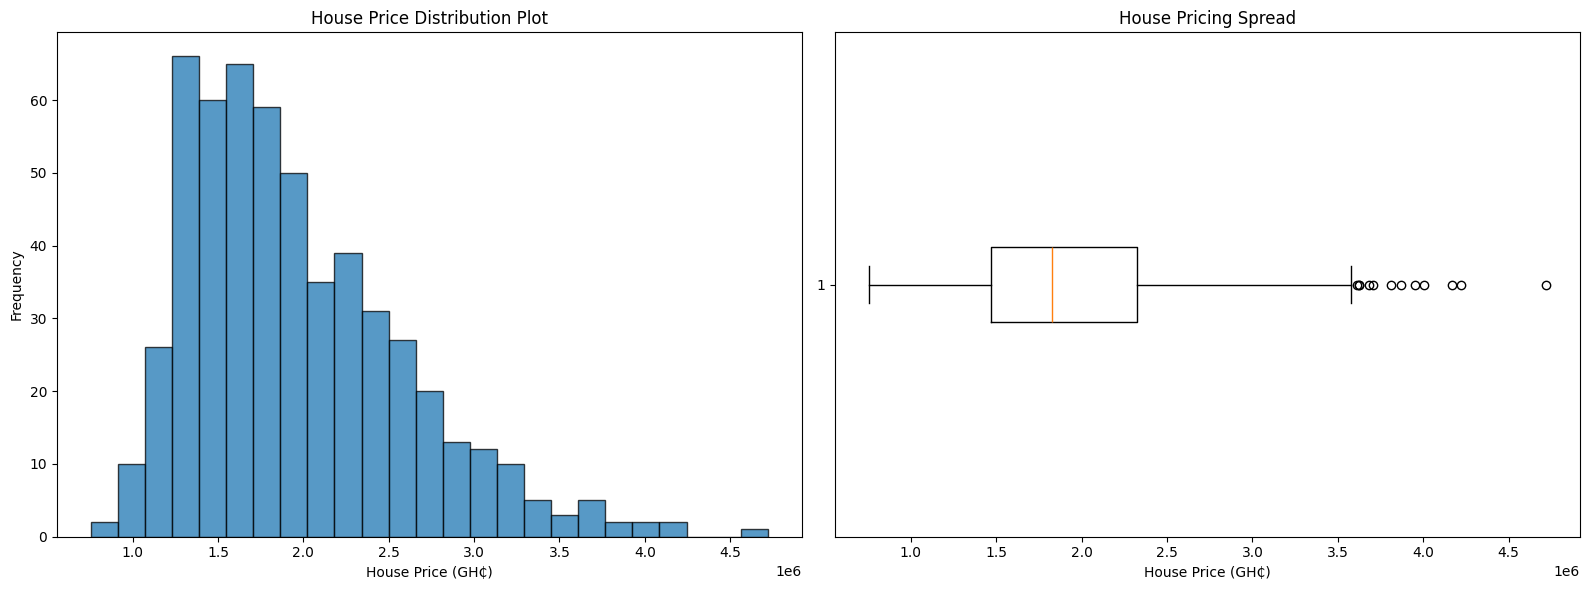

In [9]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.title("House Price Distribution Plot")
plt.hist(df["price"], bins=25, edgecolor="black", alpha=0.75)
plt.xlabel("House Price (GH₵)")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.boxplot(df["price"], vert=False)
plt.title("House Pricing Spread")
plt.xlabel("House Price (GH₵)")

plt.tight_layout()
plt.show()

In [10]:
print(
    df["price"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.85, 0.90, 1.00]
    )
)

count    5.450000e+02
mean     1.957385e+06
std      6.336256e+05
min      7.550000e+05
25%      1.470000e+06
50%      1.825000e+06
75%      2.325000e+06
85%      2.612000e+06
90%      2.820000e+06
100%     4.720000e+06
max      4.720000e+06
Name: price, dtype: float64


### Inference

The house-price distribution can be inspected for skewness and possible outliers.
The mean and median should be compared before drawing conclusions about the shape of the distribution.

## Visualising Categorical Data

In [11]:
categorical_list = [x for x in df.columns if df[x].dtype == "object"]
print("Categorical columns:")
print(categorical_list)

Categorical columns:
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus', 'location', 'city', 'country']


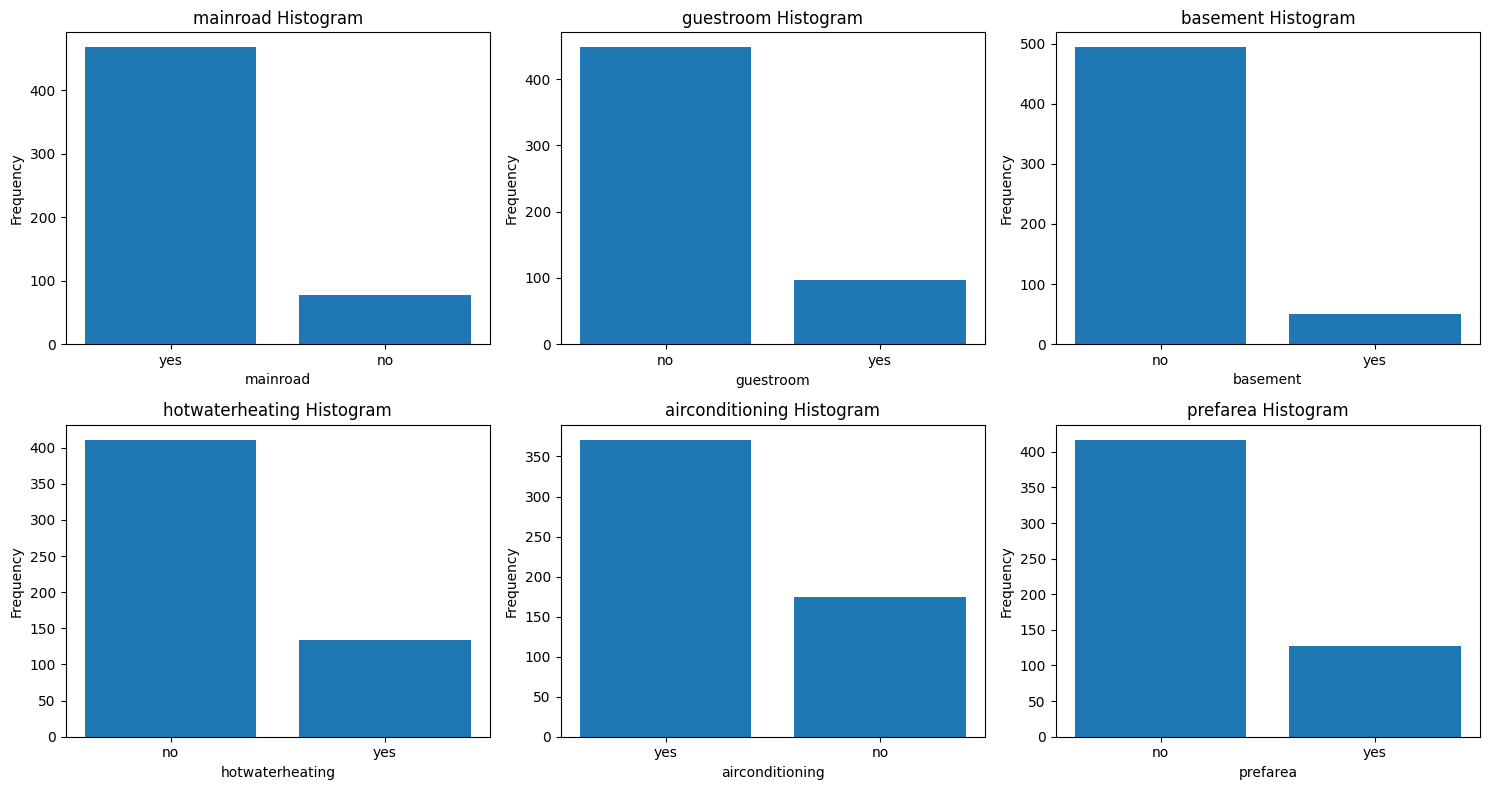

In [12]:
housing_categorical = [
    "mainroad", "guestroom", "basement",
    "hotwaterheating", "airconditioning", "prefarea"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.ravel(), housing_categorical):
    counts = df[col].value_counts()
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(f"{col} Histogram")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

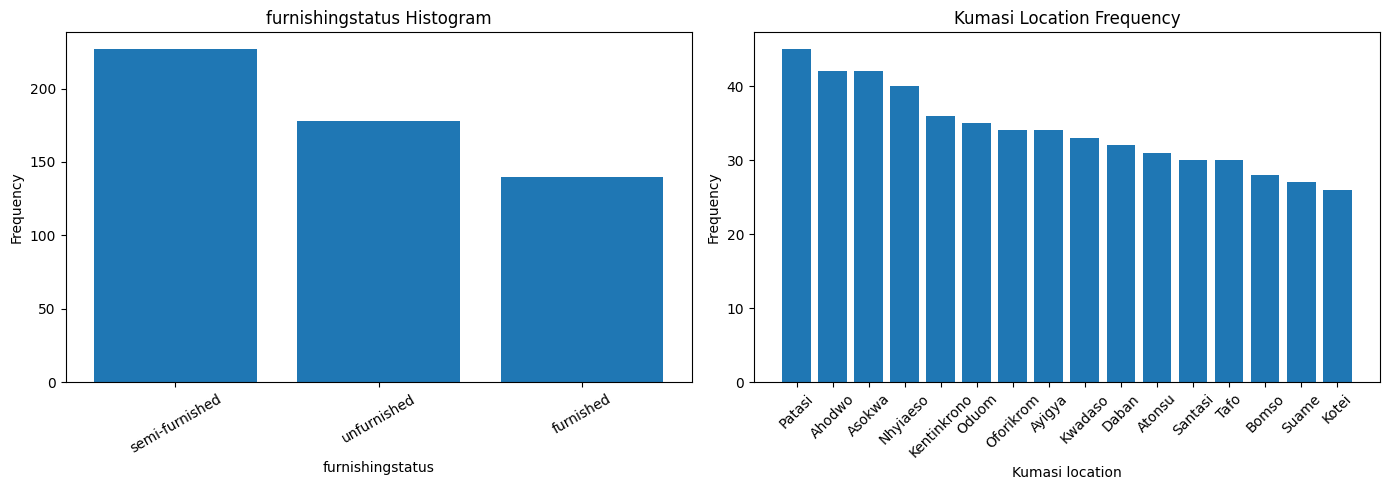

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

furnish_counts = df["furnishingstatus"].value_counts()
axes[0].bar(furnish_counts.index.astype(str), furnish_counts.values)
axes[0].set_title("furnishingstatus Histogram")
axes[0].set_xlabel("furnishingstatus")
axes[0].set_ylabel("Frequency")
axes[0].tick_params(axis="x", rotation=30)

loc_counts = df["location"].value_counts().sort_values(ascending=False)
axes[1].bar(loc_counts.index.astype(str), loc_counts.values)
axes[1].set_title("Kumasi Location Frequency")
axes[1].set_xlabel("Kumasi location")
axes[1].set_ylabel("Frequency")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

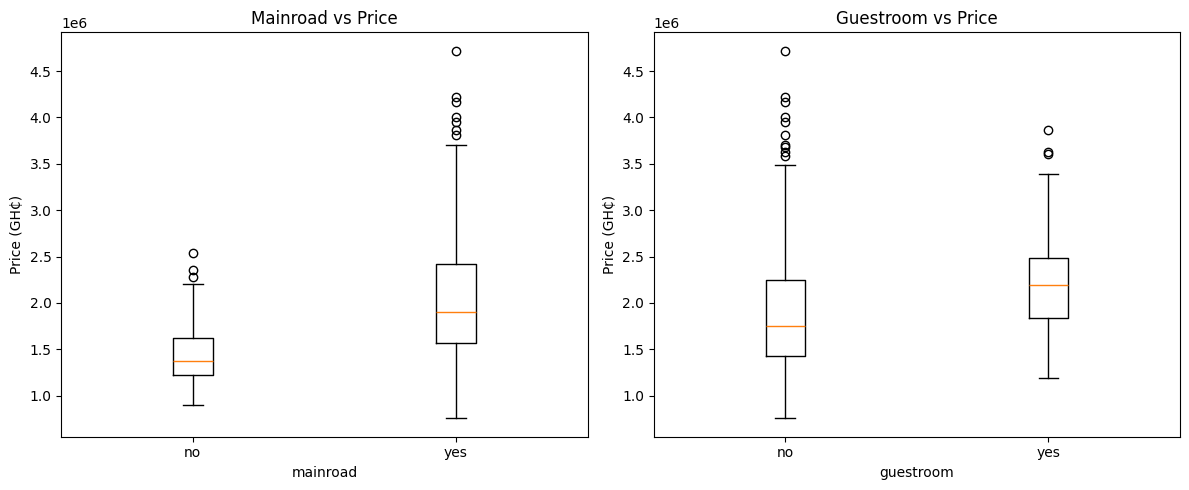

In [14]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.title("Mainroad vs Price")
groups = [df.loc[df["mainroad"] == v, "price"].values for v in sorted(df["mainroad"].unique())]
plt.boxplot(groups, labels=sorted(df["mainroad"].unique()))
plt.xlabel("mainroad")
plt.ylabel("Price (GH₵)")

plt.subplot(1, 2, 2)
plt.title("Guestroom vs Price")
groups = [df.loc[df["guestroom"] == v, "price"].values for v in sorted(df["guestroom"].unique())]
plt.boxplot(groups, labels=sorted(df["guestroom"].unique()))
plt.xlabel("guestroom")
plt.ylabel("Price (GH₵)")

plt.tight_layout()
plt.show()

**Inference:** The boxplots help compare the distribution of house prices for properties with and without the selected categorical features.

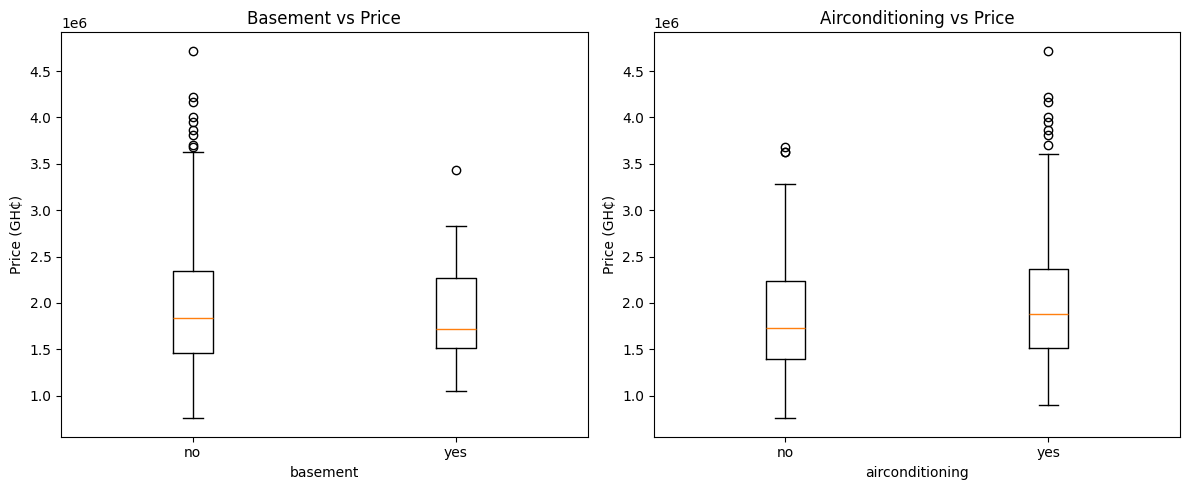

In [15]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.title("Basement vs Price")
groups = [df.loc[df["basement"] == v, "price"].values for v in sorted(df["basement"].unique())]
plt.boxplot(groups, labels=sorted(df["basement"].unique()))
plt.xlabel("basement")
plt.ylabel("Price (GH₵)")

plt.subplot(1, 2, 2)
plt.title("Airconditioning vs Price")
groups = [df.loc[df["airconditioning"] == v, "price"].values for v in sorted(df["airconditioning"].unique())]
plt.boxplot(groups, labels=sorted(df["airconditioning"].unique()))
plt.xlabel("airconditioning")
plt.ylabel("Price (GH₵)")

plt.tight_layout()
plt.show()

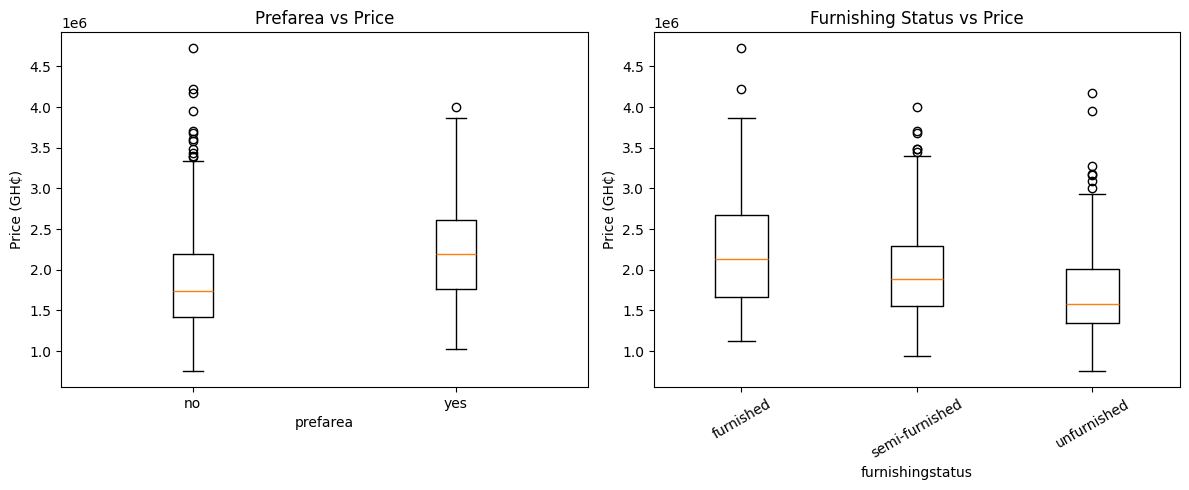

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.title("Prefarea vs Price")
groups = [df.loc[df["prefarea"] == v, "price"].values for v in sorted(df["prefarea"].unique())]
plt.boxplot(groups, labels=sorted(df["prefarea"].unique()))
plt.xlabel("prefarea")
plt.ylabel("Price (GH₵)")

plt.subplot(1, 2, 2)
plt.title("Furnishing Status vs Price")
furnish_order = sorted(df["furnishingstatus"].unique())
groups = [df.loc[df["furnishingstatus"] == v, "price"].values for v in furnish_order]
plt.boxplot(groups, labels=furnish_order)
plt.xlabel("furnishingstatus")
plt.ylabel("Price (GH₵)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

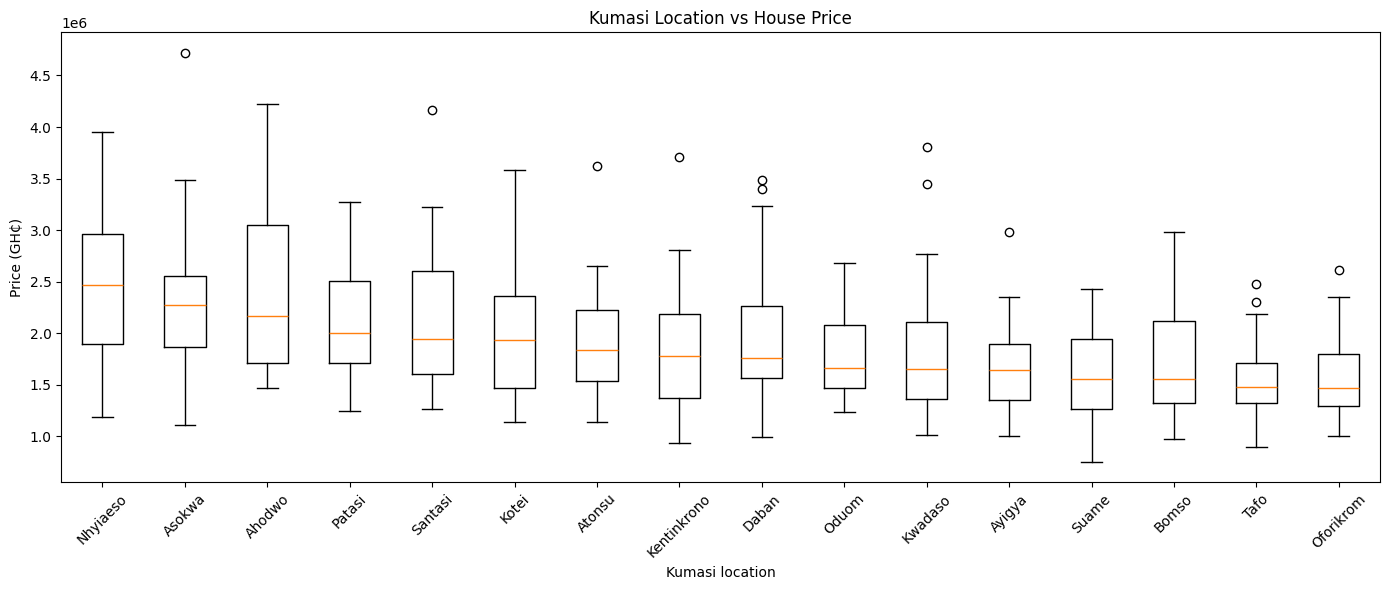

In [17]:
plt.figure(figsize=(14, 6))
loc_order = df.groupby("location")["price"].median().sort_values(ascending=False).index.tolist()
groups = [df.loc[df["location"] == v, "price"].values for v in loc_order]
plt.boxplot(groups, labels=loc_order)
plt.title("Kumasi Location vs House Price")
plt.xlabel("Kumasi location")
plt.ylabel("Price (GH₵)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Inference:** Location is included because the supplied dataset contains Kumasi neighbourhood information. Differences between neighbourhood price distributions can be examined without assuming that every area has the same effect.

## Visualising numerical data

In [18]:
numerical_list = [x for x in df.columns if df[x].dtype in ("int64", "float64")]
print("Numerical columns:")
print(numerical_list)

Numerical columns:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']


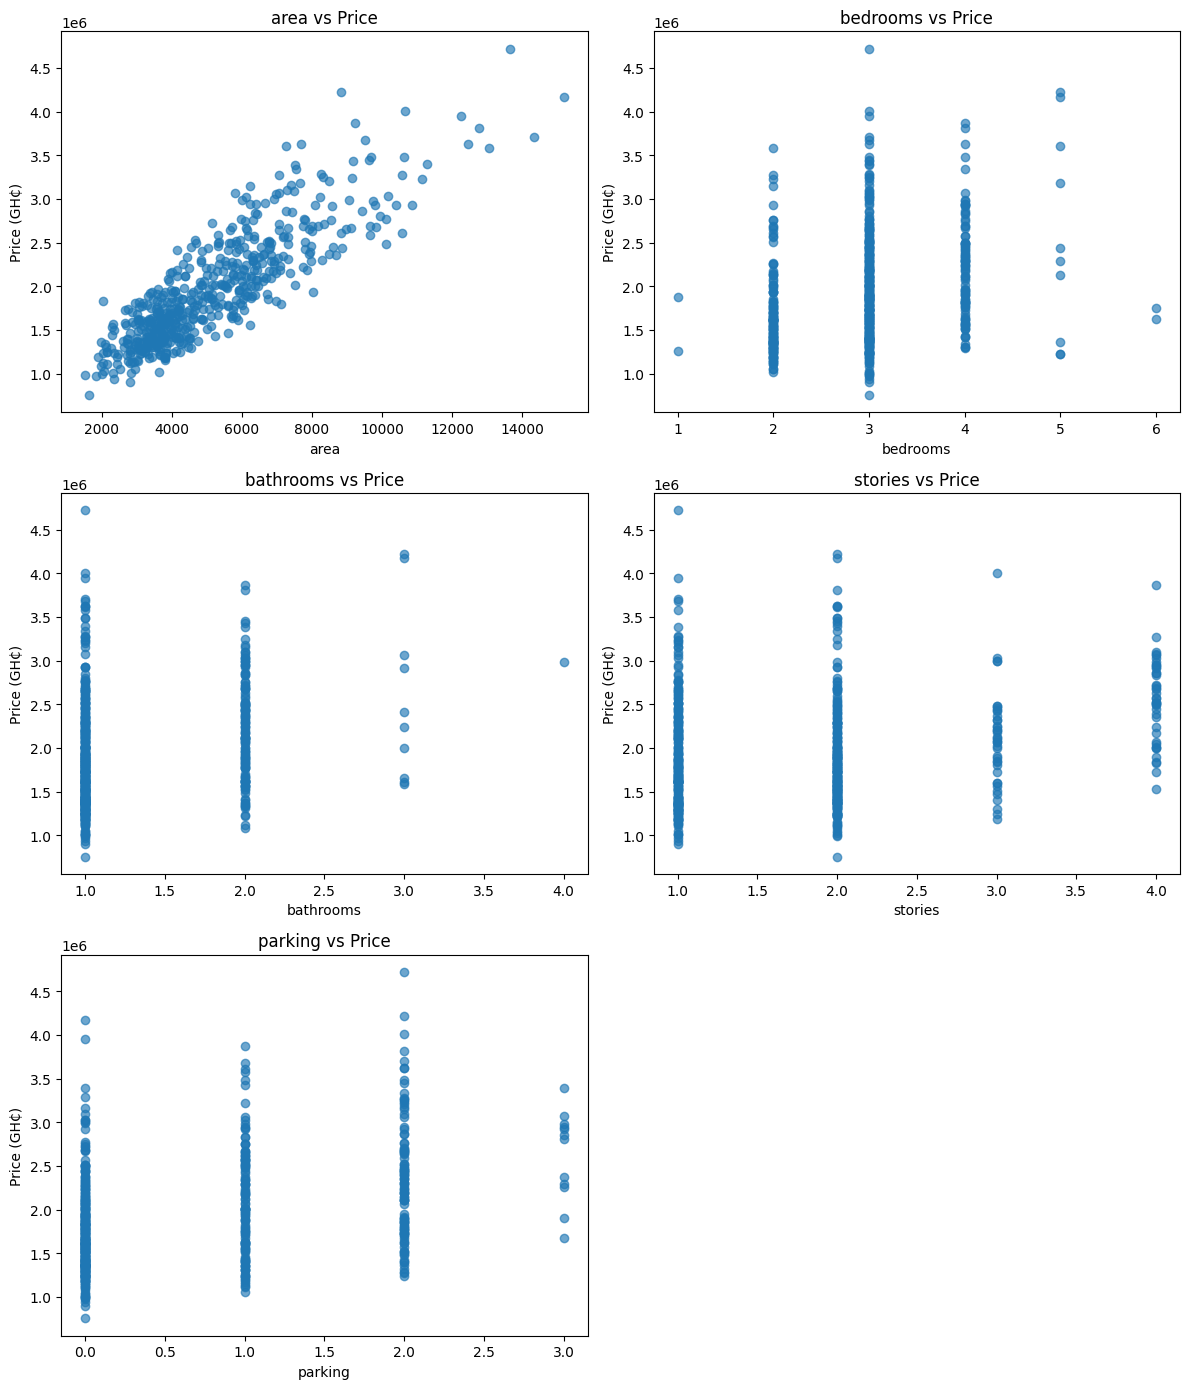

In [19]:
def scatter_price(x, fig):
    plt.subplot(3, 2, fig)
    plt.scatter(df[x], df["price"], alpha=0.65)
    plt.title(f"{x} vs Price")
    plt.ylabel("Price (GH₵)")
    plt.xlabel(x)

plt.figure(figsize=(12, 14))

scatter_price("area", 1)
scatter_price("bedrooms", 2)
scatter_price("bathrooms", 3)
scatter_price("stories", 4)
scatter_price("parking", 5)

plt.tight_layout()
plt.show()

**Inference:** Among the numerical variables, `area` is expected to be especially informative because house size has a direct relationship with usable residential space. The scatter plot shows the relationship in this supplied dataset.

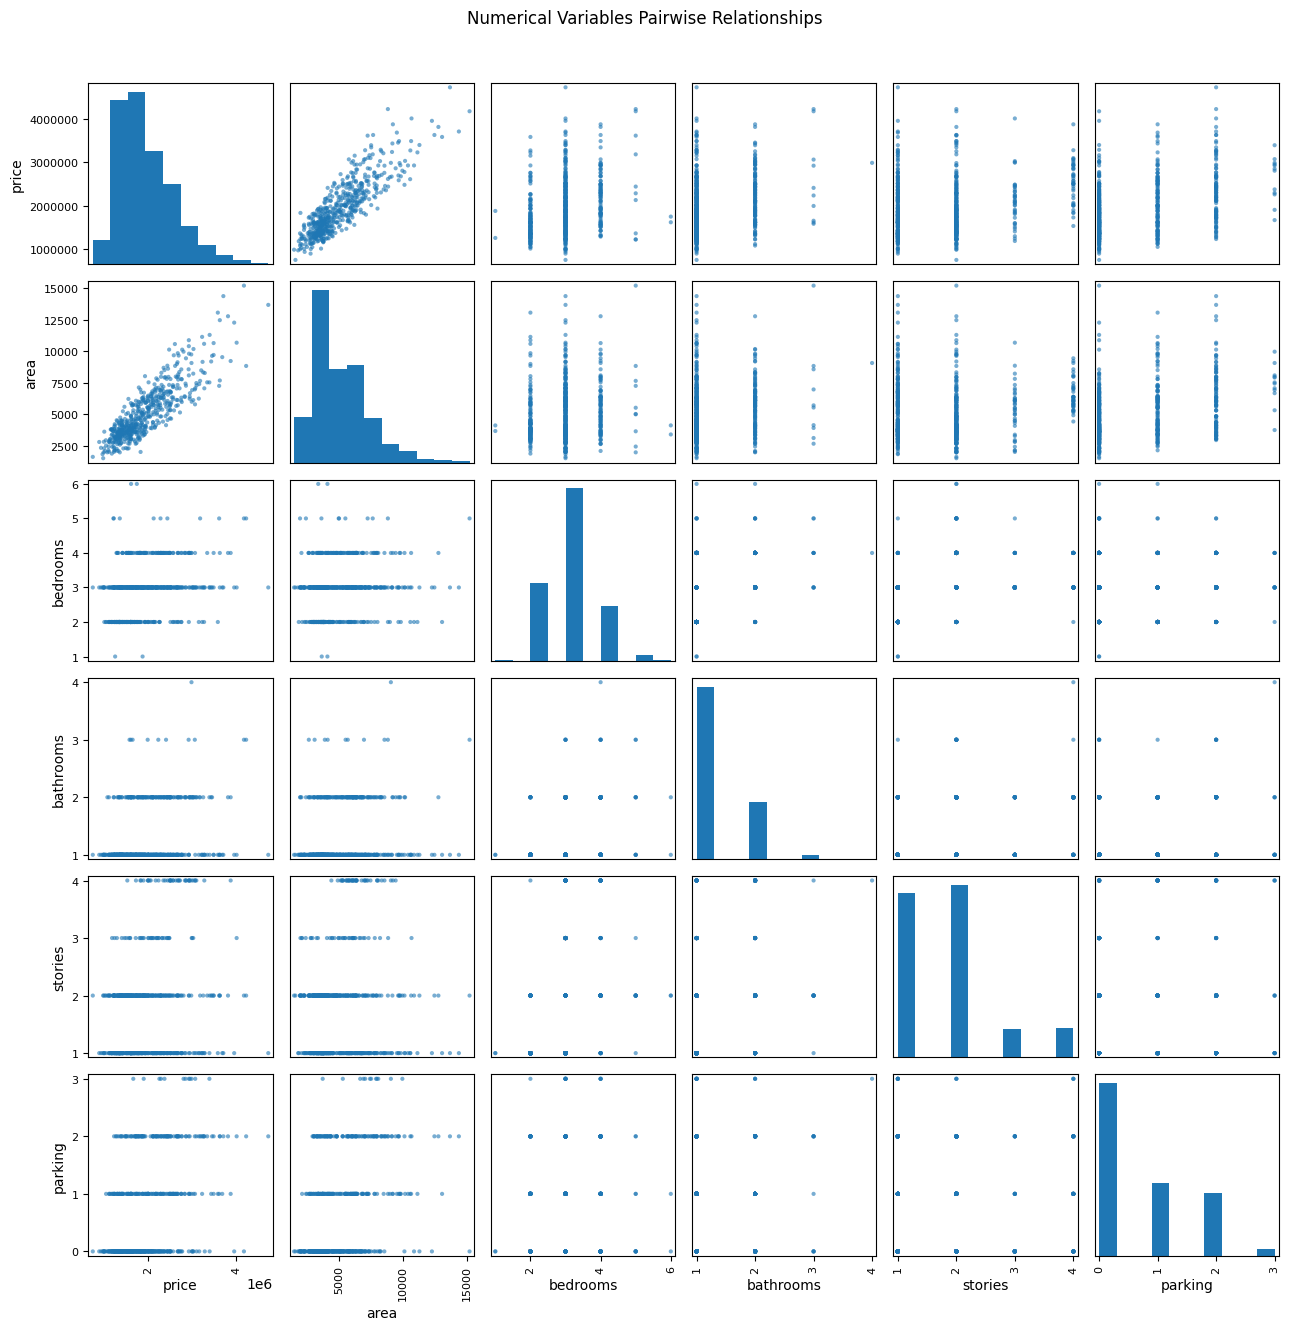

In [20]:
from pandas.plotting import scatter_matrix

numeric_for_pairplot = ["price", "area", "bedrooms", "bathrooms", "stories", "parking"]
scatter_matrix(
    df[numeric_for_pairplot],
    figsize=(13, 13),
    diagonal="hist",
    alpha=0.6
)
plt.suptitle("Numerical Variables Pairwise Relationships", y=1.02)
plt.tight_layout()
plt.show()

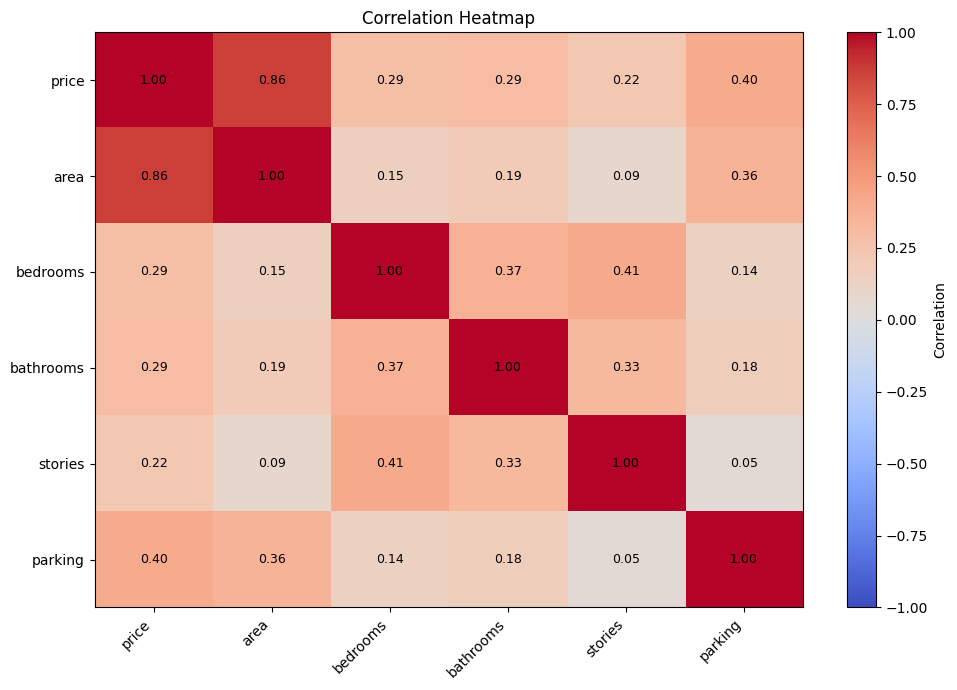

In [21]:
cor_matrix = df[numerical_list].corr()

plt.figure(figsize=(10, 7))
plt.imshow(cor_matrix, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(cor_matrix.columns)), cor_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(cor_matrix.index)), cor_matrix.index)

for i in range(cor_matrix.shape[0]):
    for j in range(cor_matrix.shape[1]):
        plt.text(j, i, f"{cor_matrix.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=9)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Dummy Variables

In [22]:
# Work on a modeling copy.
# city and country contain a single constant value in this dataset,
# so they do not add predictive information and are removed.
df_model = df.drop(columns=["city", "country"]).copy()

categorical_for_model = [
    "mainroad", "guestroom", "basement", "hotwaterheating",
    "airconditioning", "prefarea", "furnishingstatus", "location"
]

df_model = pd.get_dummies(
    df_model,
    columns=categorical_for_model,
    drop_first=True,
    dtype=int
)

df_model.head()

,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished,location_Asokwa,location_Atonsu,location_Ayigya,location_Bomso,location_Daban,location_Kentinkrono,location_Kotei,location_Kwadaso,location_Nhyiaeso,location_Oduom,location_Oforikrom,location_Patasi,location_Santasi,location_Suame,location_Tafo
0,2425000,7806,4,2,3,2,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
1,2985000,9060,4,4,4,3,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
2,3450000,9623,3,2,2,2,1,0,0,1,1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
3,2375000,7907,4,2,2,3,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4,3340000,7529,4,1,2,2,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [23]:
df_model.shape

(545, 29)

The categorical columns are converted to dummy variables so that the machine-learning model can use them as numerical predictors. `location` is included because this is specifically a Kumasi housing dataset.

## Train/Test Split

In [24]:
from sklearn.model_selection import train_test_split

np.random.seed(0)

X = df_model.drop("price", axis=1)
y = df_model["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.75,
    test_size=0.25,
    random_state=100
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 408
Testing rows: 137


## Feature Scaling

In [25]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

numeric_features = ["area", "bedrooms", "bathrooms", "stories", "parking"]

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit the scaler on training data only, then apply it to both sets.
X_train_scaled[numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)
X_test_scaled[numeric_features] = scaler.transform(
    X_test[numeric_features]
)

X_train_scaled.head()

,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished,location_Asokwa,location_Atonsu,location_Ayigya,location_Bomso,location_Daban,location_Kentinkrono,location_Kotei,location_Kwadaso,location_Nhyiaeso,location_Oduom,location_Oforikrom,location_Patasi,location_Santasi,location_Suame,location_Tafo
333,0.103059,0.4,0.0,0.333333,0.000000,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
429,0.242141,0.6,0.0,0.333333,0.000000,1,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
18,0.234579,0.4,0.5,0.333333,0.666667,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
480,0.155820,0.4,0.0,0.333333,0.333333,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
505,0.156160,0.4,0.0,0.333333,0.000000,1,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0


## Dividing data into X and y variables

In [26]:
y_train = y_train.copy()
y_test = y_test.copy()

## Recursive Feature Elimination (RFE)

In [27]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

rfe = RFE(
    estimator=LinearRegression(),
    n_features_to_select=10
)
rfe = rfe.fit(X_train_scaled, y_train)

feature_ranking = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Selected": rfe.support_,
    "Ranking": rfe.ranking_
}).sort_values(["Selected", "Ranking"], ascending=[False, True])

feature_ranking

,Feature,Selected,Ranking
0,area,True,1
1,bedrooms,True,1
14,location_Atonsu,True,1
15,location_Ayigya,True,1
18,location_Kentinkrono,True,1
19,location_Kotei,True,1
22,location_Oduom,True,1
23,location_Oforikrom,True,1
26,location_Suame,True,1
27,location_Tafo,True,1


In [28]:
selected_features = X_train_scaled.columns[rfe.support_].tolist()
print("Selected features:")
print(selected_features)

Selected features:
['area', 'bedrooms', 'location_Atonsu', 'location_Ayigya', 'location_Kentinkrono', 'location_Kotei', 'location_Oduom', 'location_Oforikrom', 'location_Suame', 'location_Tafo']


In [29]:
X_train_rfe = X_train_scaled[selected_features]
X_train_rfe.head()

,area,bedrooms,location_Atonsu,location_Ayigya,location_Kentinkrono,location_Kotei,location_Oduom,location_Oforikrom,location_Suame,location_Tafo
333,0.103059,0.4,0,0,0,0,0,1,0,0
429,0.242141,0.6,1,0,0,0,0,0,0,0
18,0.234579,0.4,0,0,0,0,0,0,0,0
480,0.155820,0.4,0,0,0,0,0,0,0,0
505,0.156160,0.4,0,0,0,0,0,0,0,0


## Model Building with OLS

In [30]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def build_model(X, y):
    X_const = sm.add_constant(X, has_constant="add")
    lm = sm.OLS(y, X_const).fit()
    print(lm.summary())
    return X_const

def checkVIF(X):
    vif = pd.DataFrame()
    vif["Features"] = X.columns
    vif["VIF"] = [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
    vif["VIF"] = vif["VIF"].replace([np.inf, -np.inf], np.nan)
    vif["VIF"] = vif["VIF"].round(2)
    return vif.sort_values(by="VIF", ascending=False)

### MODEL 1

In [31]:
X_train_new = build_model(X_train_rfe, y_train)

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.880
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     290.9
Date:                Tue, 22 Sep 2026   Prob (F-statistic):          7.77e-176
Time:                        10:54:25   Log-Likelihood:                -5595.8
No. Observations:                 408   AIC:                         1.121e+04
Df Residuals:                     397   BIC:                         1.126e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  1.02e+06 

The first OLS model provides coefficient estimates and p-values for the features selected by RFE.

In [32]:
# Check statistical significance before simplifying the model.
model1_pvalues = (
    sm.OLS(y_train, X_train_new).fit()
    .pvalues
    .sort_values()
)
model1_pvalues

area                    1.305433e-166
const                    6.059529e-97
location_Tafo            1.206395e-26
location_Oforikrom       6.995813e-21
bedrooms                 1.758454e-20
location_Kentinkrono     2.175368e-14
location_Suame           2.916850e-13
location_Kotei           1.848691e-12
location_Oduom           8.416520e-12
location_Ayigya          9.917522e-12
location_Atonsu          5.944007e-10
dtype: float64

### Model 2 – retain statistically supported predictors

In [33]:
lm_model2 = sm.OLS(y_train, X_train_new).fit()

# Keep non-constant features with p <= 0.05.
supported_features = [
    feature
    for feature in X_train_rfe.columns
    if lm_model2.pvalues.get(feature, 1.0) <= 0.05
]

if len(supported_features) == 0:
    supported_features = selected_features.copy()

X_train_new = sm.add_constant(
    X_train_scaled[supported_features],
    has_constant="add"
)

lm_model2 = sm.OLS(y_train, X_train_new).fit()
print(lm_model2.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.880
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     290.9
Date:                Tue, 22 Sep 2026   Prob (F-statistic):          7.77e-176
Time:                        10:54:25   Log-Likelihood:                -5595.8
No. Observations:                 408   AIC:                         1.121e+04
Df Residuals:                     397   BIC:                         1.126e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  1.02e+06 

In [34]:
checkVIF(X_train_new)

,Features,VIF
0,const,10.83
4,location_Ayigya,1.05
3,location_Atonsu,1.05
7,location_Oduom,1.05
8,location_Oforikrom,1.05
5,location_Kentinkrono,1.05
6,location_Kotei,1.05
10,location_Tafo,1.05
1,area,1.03
9,location_Suame,1.03


### Model 3 – final model

The final model is checked for multicollinearity using VIF and retains the feature set that remains suitable for this supplied dataset.

In [35]:
# Iteratively remove only predictors with very high VIF (> 10).
final_features = supported_features.copy()

while len(final_features) > 1:
    X_tmp = sm.add_constant(
        X_train_scaled[final_features],
        has_constant="add"
    )
    vif_tmp = checkVIF(X_tmp).set_index("Features")["VIF"].drop(
        labels=["const"],
        errors="ignore"
    )

    if vif_tmp.empty or vif_tmp.max() <= 10:
        break

    feature_to_drop = vif_tmp.idxmax()
    final_features.remove(feature_to_drop)

X_train_final = sm.add_constant(
    X_train_scaled[final_features],
    has_constant="add"
)

lm = sm.OLS(y_train, X_train_final).fit()
print(lm.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.880
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     290.9
Date:                Tue, 22 Sep 2026   Prob (F-statistic):          7.77e-176
Time:                        10:54:25   Log-Likelihood:                -5595.8
No. Observations:                 408   AIC:                         1.121e+04
Df Residuals:                     397   BIC:                         1.126e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  1.02e+06 

In [36]:
checkVIF(X_train_final)

,Features,VIF
0,const,10.83
4,location_Ayigya,1.05
3,location_Atonsu,1.05
7,location_Oduom,1.05
8,location_Oforikrom,1.05
5,location_Kentinkrono,1.05
6,location_Kotei,1.05
10,location_Tafo,1.05
1,area,1.03
9,location_Suame,1.03


## Model is ready – let's verify the model through Residual Analysis

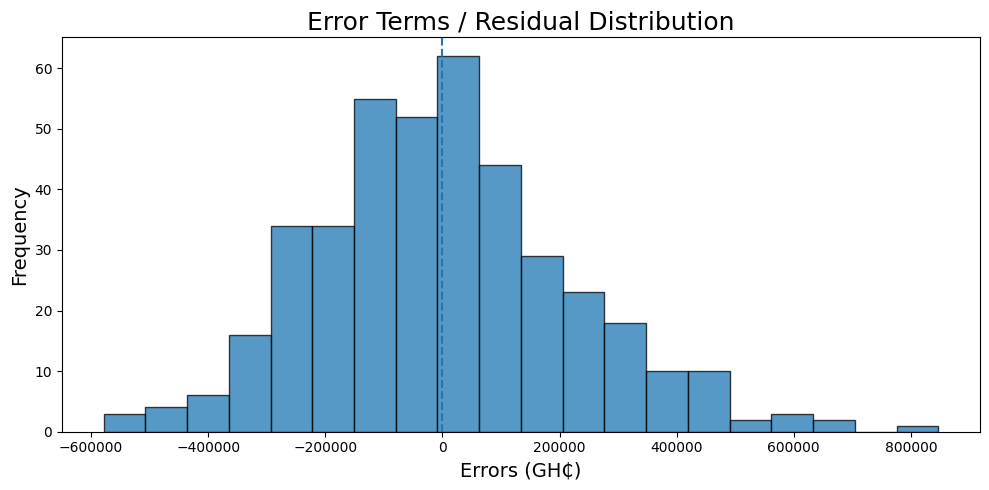

In [37]:
# Predictions and residuals on the training set
y_train_price = lm.predict(X_train_final)
residuals = y_train - y_train_price

plt.figure(figsize=(10, 5))
plt.hist(residuals, bins=20, edgecolor="black", alpha=0.75)
plt.axvline(0, linestyle="--")
plt.title("Error Terms / Residual Distribution", fontsize=18)
plt.xlabel("Errors (GH₵)", fontsize=14)
plt.ylabel("Frequency", fontsize=14)
plt.tight_layout()
plt.show()

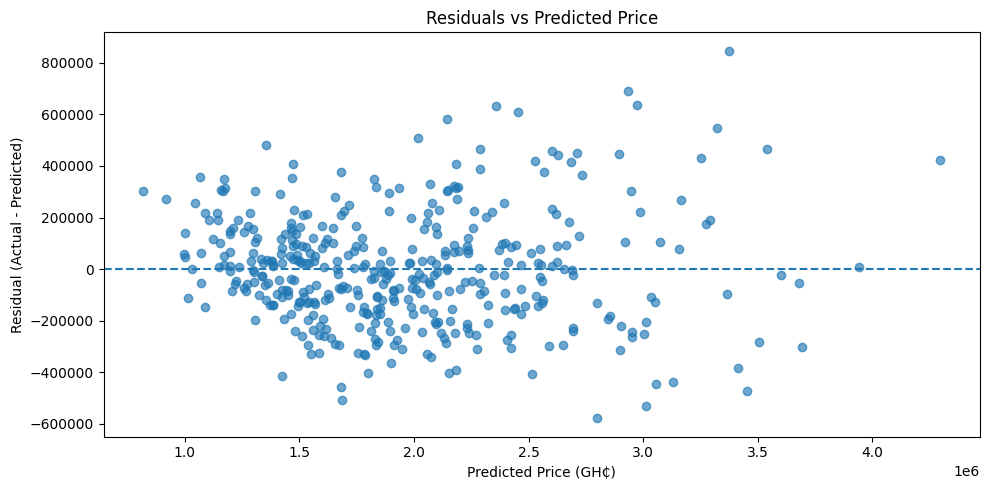

In [38]:
plt.figure(figsize=(10, 5))
plt.scatter(y_train_price, residuals, alpha=0.65)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted Price")
plt.xlabel("Predicted Price (GH₵)")
plt.ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

**Inference:** The residual plots are used to inspect whether the error terms appear reasonably centered around zero and whether there is an obvious pattern. These are diagnostics rather than proof that every linear-regression assumption is satisfied.

## Predicting on the Test Set

In [39]:
X_test_final = sm.add_constant(
    X_test_scaled[final_features],
    has_constant="add"
)

y_pred = lm.predict(X_test_final)

results = pd.DataFrame({
    "Actual Price (GH₵)": y_test.values,
    "Predicted Price (GH₵)": y_pred.values,
    "Absolute Error (GH₵)": np.abs(y_test.values - y_pred.values)
})

results.head(10)

,Actual Price (GH₵),Predicted Price (GH₵),Absolute Error (GH₵)
0,1395000,1.526947e+06,131946.768799
1,2080000,2.254292e+06,174291.574729
2,2925000,3.081247e+06,156247.299315
3,1895000,1.780845e+06,114154.591730
4,1915000,2.295464e+06,380464.123813
5,2160000,1.854454e+06,305545.747307
6,2670000,2.540779e+06,129221.390181
7,2355000,2.659642e+06,304642.329842
8,2510000,2.387874e+06,122126.015769
9,2360000,2.060790e+06,299210.382162


## Evaluation of the Model

In [40]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

evaluation = pd.DataFrame({
    "Metric": ["R-squared (R²)", "MAE", "RMSE"],
    "Value": [r2, mae, rmse]
})

evaluation

,Metric,Value
0,R-squared (R²),0.838825
1,MAE,198106.933583
2,RMSE,255774.753001


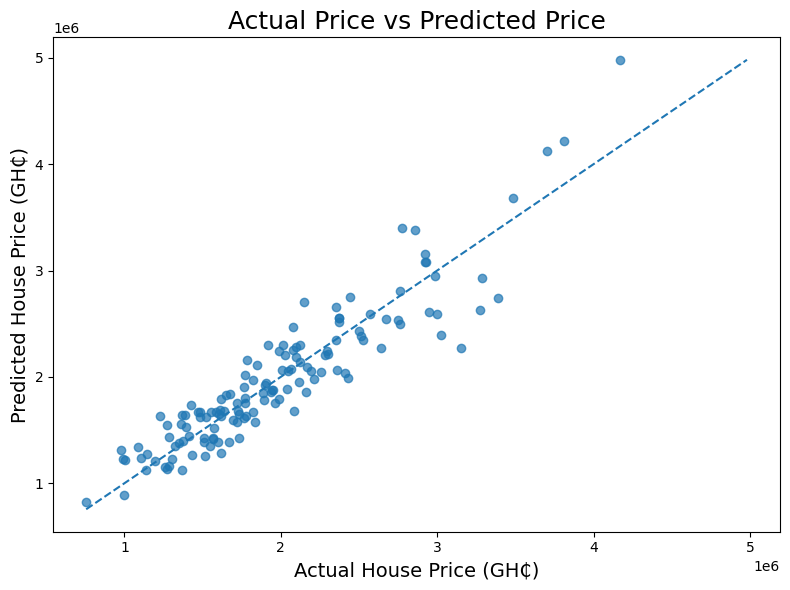

In [41]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7)

line_min = min(y_test.min(), y_pred.min())
line_max = max(y_test.max(), y_pred.max())
plt.plot([line_min, line_max], [line_min, line_max], linestyle="--")

plt.title("Actual Price vs Predicted Price", fontsize=18)
plt.xlabel("Actual House Price (GH₵)", fontsize=14)
plt.ylabel("Predicted House Price (GH₵)", fontsize=14)
plt.tight_layout()
plt.show()

## Example Prediction

The example below shows how the trained model can be used for a new Kumasi house. The property information is only an example input for demonstrating the prediction code.

In [42]:
# Example new property
example_house = {
    "area": 5500,
    "bedrooms": 3,
    "bathrooms": 2,
    "stories": 2,
    "parking": 1,
    "mainroad": "yes",
    "guestroom": "no",
    "basement": "no",
    "hotwaterheating": "no",
    "airconditioning": "yes",
    "prefarea": "yes",
    "furnishingstatus": "semi-furnished",
    "location": "Ahodwo"
}

example_df = pd.DataFrame([example_house])

# Create dummy columns using the same training structure.
example_encoded = pd.get_dummies(
    example_df,
    columns=categorical_for_model,
    drop_first=True,
    dtype=int
)

example_encoded = example_encoded.reindex(
    columns=X.columns,
    fill_value=0
)

example_scaled = example_encoded.copy()
example_scaled[numeric_features] = scaler.transform(
    example_encoded[numeric_features]
)

example_final = sm.add_constant(
    example_scaled[final_features],
    has_constant="add"
)

predicted_price = float(lm.predict(example_final).iloc[0])

print(f"Estimated example house price: GH₵{predicted_price:,.2f}")

Estimated example house price: GH₵2,232,794.94


## Final Model Summary

The final section reports the selected features, test-set evaluation metrics, and the fitted OLS model summary. The model should be evaluated using the supplied dataset's limitations in mind.

In [43]:
print("Final selected features:")
for feature in final_features:
    print(" -", feature)

print("\nTest-set metrics")
print(f"R²   : {r2:.4f}")
print(f"MAE  : GH₵{mae:,.2f}")
print(f"RMSE : GH₵{rmse:,.2f}")

print("\nOLS Model Summary")
print(lm.summary())

Final selected features:
 - area
 - bedrooms
 - location_Atonsu
 - location_Ayigya
 - location_Kentinkrono
 - location_Kotei
 - location_Oduom
 - location_Oforikrom
 - location_Suame
 - location_Tafo

Test-set metrics
R²   : 0.8388
MAE  : GH₵198,106.93
RMSE : GH₵255,774.75

OLS Model Summary
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.880
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     290.9
Date:                Tue, 22 Sep 2026   Prob (F-statistic):          7.77e-176
Time:                        10:54:26   Log-Likelihood:                -5595.8
No. Observations:                 408   AIC:                         1.121e+04
Df Residuals:                     397   BIC:                         1.126e+04
Df Model:                          10                                      

### Conclusion

This notebook provides a complete machine-learning workflow for **Kumasi Ghana house-price prediction** using the supplied CSV dataset. It follows the structure of the referenced regression notebook while adding the Kumasi `location` field and an example prediction for a new property.

In [44]:
import joblib

model_bundle = {
    "model": lm,
    "scaler": scaler,
    "numeric_features": numeric_features,
    "categorical_for_model": categorical_for_model,
    "model_columns": X.columns.tolist(),
    "final_features": final_features,
    "target": "price",
    "currency": "GHS (GH₵)",
    "city": "Kumasi",
    "country": "Ghana"
}

MODEL_PATH = Path("kumasi_house_price_model.pkl")
joblib.dump(model_bundle, MODEL_PATH)

print(f"Saved trained model bundle to: {MODEL_PATH.resolve()}")

Saved trained model bundle to: /mnt/data/kumasi_house_price_model.pkl
